## Step 2b: Redrawing the training figures

I want the training figures to look a little bit more different then what I originally put in the training file but don't want retrain and rerun the file.



In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.ticker import MaxNLocator

print("Done")

Done


In [2]:
# overall text size
font_size = 20

# grid lines behind the charts
show_grid = True
grid_color = "#d9d9d9"
grid_style = "-"        # "-" solid, "--" dashed, ":" dotted
grid_width = 1

# one color per fold, used in the training curves
fold_colors = ["#5b2a86", "#1d3a8a", "#2a9d8f", "#e9a03b", "#c44536"]
line_width = 3

# histogram colors
bar_color = "coral"
bar_edge_color = "white"
mean_line_color = "black"

# outline colors in the example scans
expert_color = "red"
model_color = "yellow"

# where things live
outputs_dir = "project3_outputs_v2"
data_dir = os.path.join("archive", "lgg-mri-segmentation", "kaggle_3m")
figures_dir = "figures"
dpi = 200

plt.rcParams["font.size"] = font_size
plt.rcParams["axes.grid"] = show_grid
plt.rcParams["grid.color"] = grid_color
plt.rcParams["grid.linestyle"] = grid_style
plt.rcParams["grid.linewidth"] = grid_width
plt.rcParams["axes.axisbelow"] = True   # keeps the grid behind the bars and lines

os.makedirs(figures_dir, exist_ok=True)
print("Done")

Done


In [3]:
# Load the saved results
history = pd.read_csv(os.path.join(outputs_dir, "training_history.csv"))
test_scores = pd.read_csv(os.path.join(outputs_dir, "test_dice_scores.csv"))
slices = pd.read_csv(os.path.join(outputs_dir, "slices_with_genetics2.csv"))

print("Folds:", sorted(history["Fold"].unique().tolist()))
print("Epochs per fold:", history.groupby("Fold")["Epoch"].max().to_dict())
print("Test patients:", len(test_scores))
print("Mean Dice:", round(test_scores["Dice"].mean(), 4))
print("Median Dice:", round(test_scores["Dice"].median(), 4))

Folds: [0, 1, 2, 3, 4]
Epochs per fold: {0: 40, 1: 40, 2: 40, 3: 40, 4: 40}
Test patients: 110
Mean Dice: 0.7486
Median Dice: 0.8303


### Figure 1: Training curves

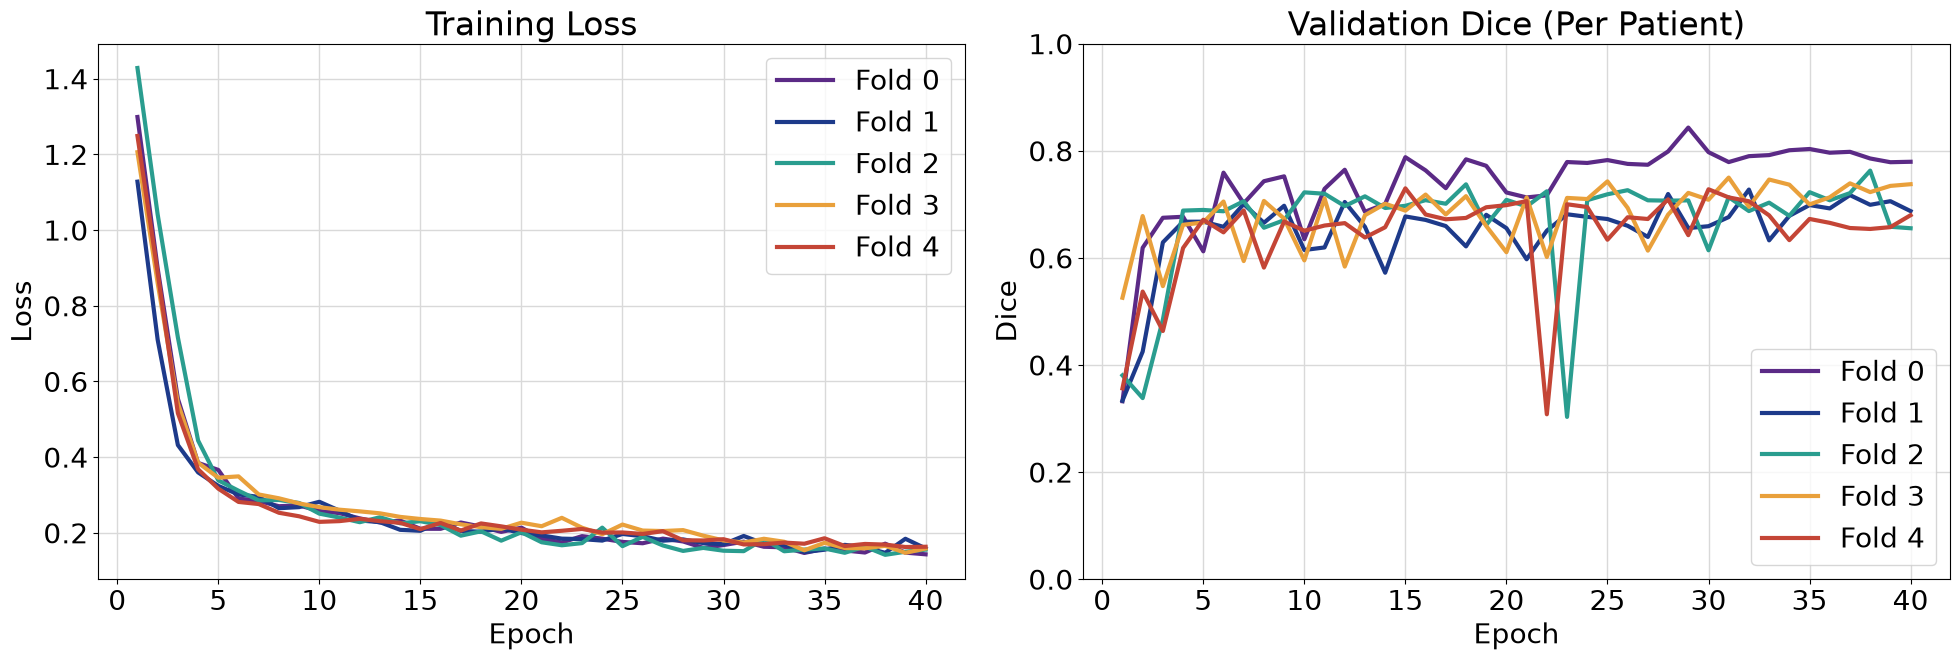

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(20, 7))

for fold in sorted(history["Fold"].unique()):
    fold_rows = history[history["Fold"] == fold]
    color = fold_colors[fold % len(fold_colors)]
    axes[0].plot(fold_rows["Epoch"], fold_rows["Loss"], color=color, linewidth=line_width, label=f"Fold {fold}")
    axes[1].plot(fold_rows["Epoch"], fold_rows["Val Dice"], color=color, linewidth=line_width, label=f"Fold {fold}")

axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[1].set_title("Validation Dice (Per Patient)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Dice")
axes[1].set_ylim(0, 1)
axes[0].legend()
axes[1].legend(loc="lower right")
for ax in axes:
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))   # whole-number epochs only

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "training_curves.png"), dpi=dpi)
plt.show()

### Figure 2: Dice scores across all test patients
Each bar counts patients. The dashed line is the mean.

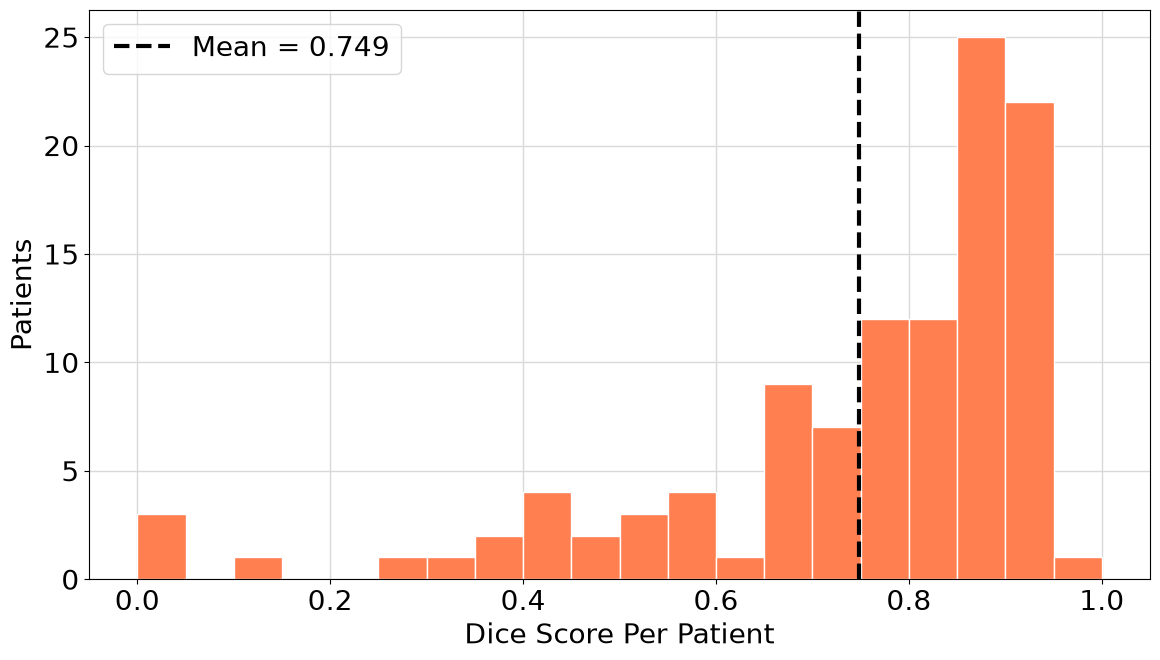

In [5]:
mean_dice = test_scores["Dice"].mean()

plt.figure(figsize=(12, 7))
plt.hist(test_scores["Dice"], bins=np.linspace(0, 1, 21), color=bar_color, edgecolor=bar_edge_color)
plt.axvline(mean_dice, color=mean_line_color, linestyle="--", linewidth=line_width,
            label=f"Mean = {mean_dice:.3f}")
plt.xlabel("Dice Score Per Patient")
plt.ylabel("Patients")
plt.legend(loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "test_dice_histogram.png"), dpi=dpi)
plt.show()

### Figure 3: Example predictions (no difference)

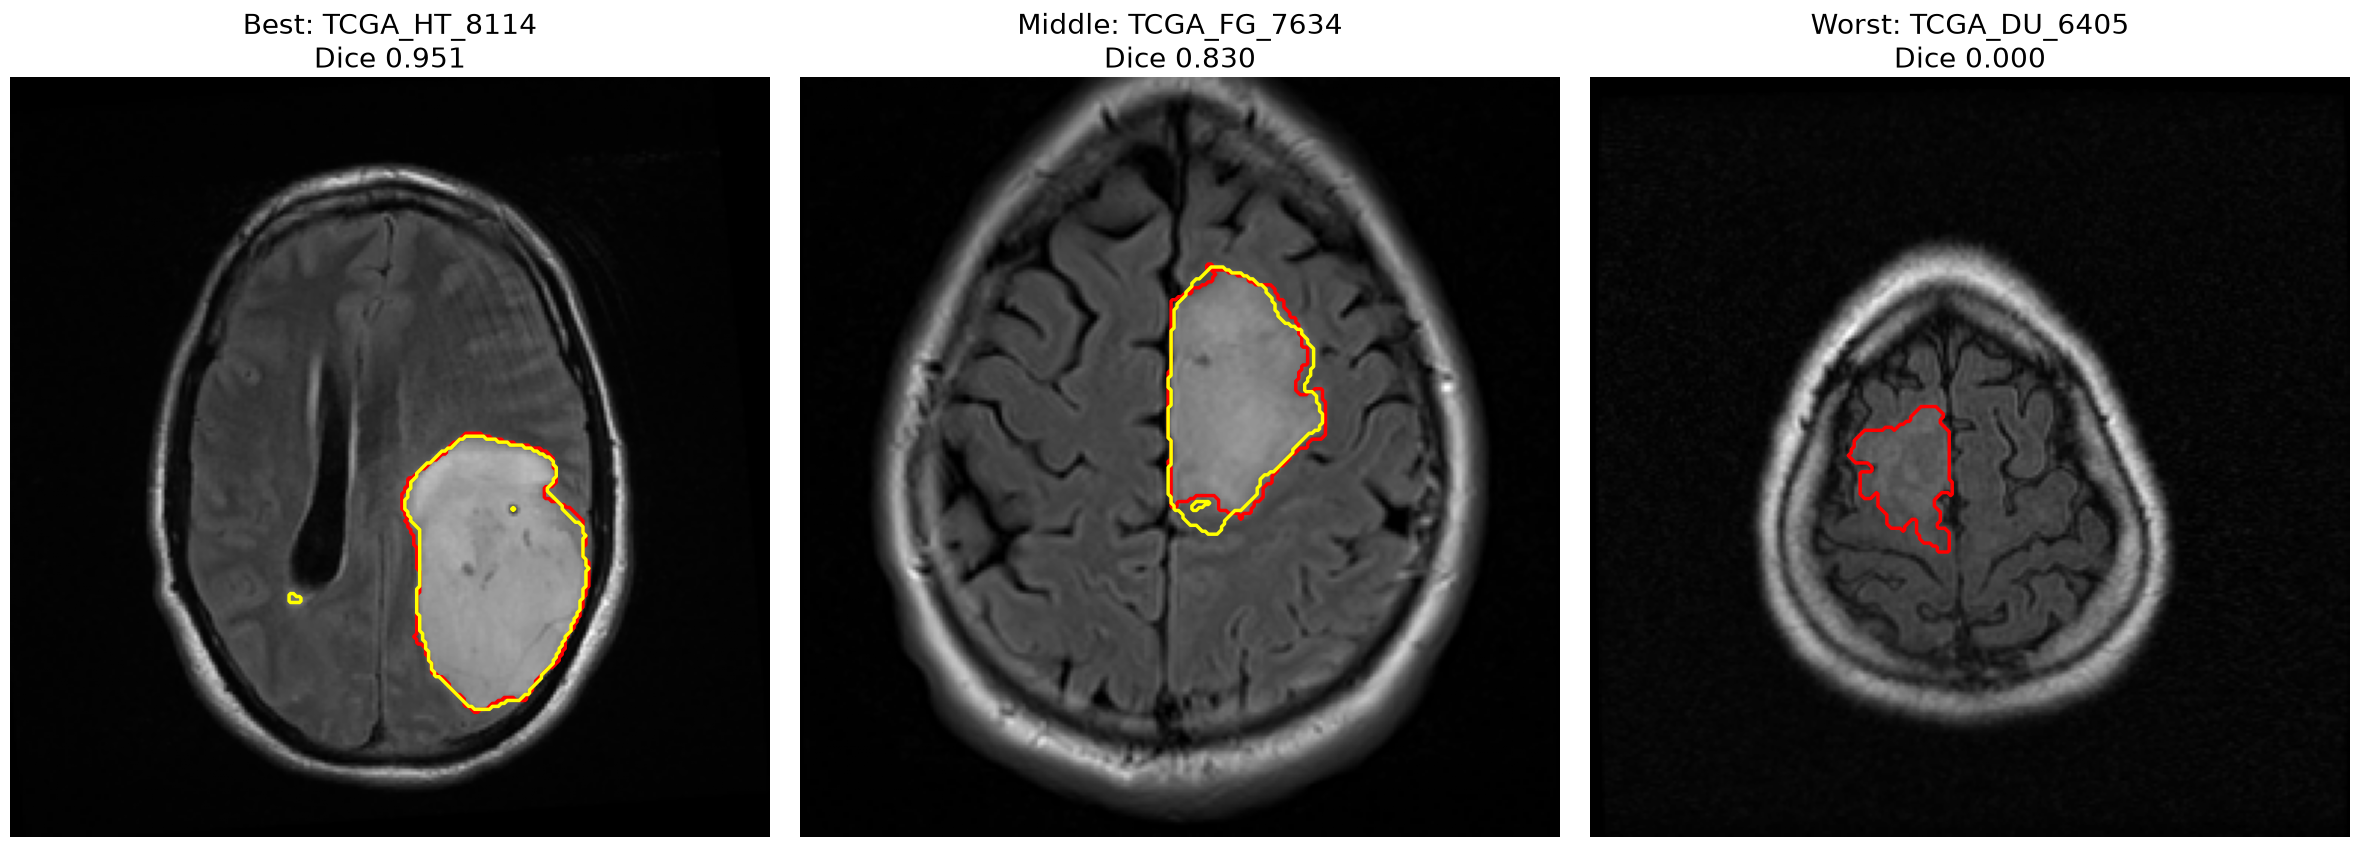

Saved all figures to the figures folder


In [6]:
def local_paths(row):
    image_name = os.path.basename(row["image_file"])
    image_path = os.path.join(data_dir, row["Folder"], image_name)
    mask_path = image_path.replace(".tif", "_mask.tif")
    pred_path = os.path.join(outputs_dir, "predictions", row["Folder"], image_name.replace(".tif", "_pred.png"))
    return image_path, mask_path, pred_path


ranked = test_scores.sort_values("Dice", ascending=False).reset_index(drop=True)
picks = [("Best", ranked.iloc[0]), ("Middle", ranked.iloc[len(ranked) // 2]), ("Worst", ranked.iloc[-1])]

fig, axes = plt.subplots(1, 3, figsize=(24, 9))
for ax, (label, pick) in zip(axes, picks):
    # find this patient's slice with the most tumor in the expert's outline
    patient_slices = slices[slices["Patient"] == pick["Patient"]]
    best_size = -1
    for _, candidate in patient_slices.iterrows():
        image_path, mask_path, pred_path = local_paths(candidate)
        size = (np.array(Image.open(mask_path)) > 0).sum()
        if size > best_size:
            best_size = size
            row = candidate

    image_path, mask_path, pred_path = local_paths(row)
    image = np.array(Image.open(image_path))
    mask = np.array(Image.open(mask_path)) > 0
    prediction = np.array(Image.open(pred_path)) > 0

    ax.imshow(image[:, :, 1], cmap="gray")
    ax.contour(mask, colors=expert_color, linewidths=2.5)
    if prediction.any():
        ax.contour(prediction, colors=model_color, linewidths=2.5)
    ax.set_title(f"{label}: {pick['Patient']}\nDice {pick['Dice']:.3f}", fontsize=font_size)
    ax.grid(False)
    ax.axis("off")

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "example_predictions.png"), dpi=dpi)
plt.show()

print("Saved all figures to the", figures_dir, "folder")